# 01 — Préparation des données (TON_IoT Network)

Entrée : `data/train_test_network.csv` · Sorties : `data/processed/*.parquet`, `config.json`, `reports/results/prep.json`

Ce notebook est le **socle commun** : tous les modèles (notebooks 02 à 06) lisent exactement les mêmes jeux *train / validation / test*.

| Notebook | Tâche | Modèle |
|---|---|---|
| 01 | Préparation, EDA, équilibrage, étude de l'encodage ordinal | — |
| 02 | Détection d'anomalies (`label`) | Random Forest |
| 03 | Détection d'anomalies (`label`) | SVM (linéaire + RBF) |
| 04 | Prédiction du type (`type`) | Random Forest Regressor |
| 05 | Prédiction du type (`type`) | XGBoost Regressor |
| 06 | Détection non supervisée (complément) | Isolation Forest |
| 07 | Tableaux comparatifs finaux | tous |

## Plan (ordre strict, anti-fuite)

1. Inspection, **validation des valeurs**, valeurs manquantes (`-` Zeek = NaN), vérification de la cible
2. Analyse exploratoire (EDA)
3. Feature engineering (ligne par ligne, sans statistique globale ; **aucun indicateur issu des IP**)
4. Colonnes écartées *sans regarder la cible* → **déduplication dans l'espace des variables candidates** → conflits → outliers
5. Split stratifié 60 / 20 / 20
6. Sélection de variables sur le **train seul**
7. **Déduplication inter-splits dans l'espace final des variables** (vérifiée par assertion : recouvrement = 0)
8. Distributions par split, aperçu de l'équilibrage (train uniquement)
9. **Étude de l'encodage ordinal** de `type` (pour les régresseurs 04/05) → choix de l'ordre
10. Sauvegarde

> **Pourquoi cette version diffère de la précédente.** L'ancienne déduplication portait sur un ensemble de colonnes plus large que
> celui des modèles ; après la sélection de variables (train seul), des lignes ne différant que par une colonne supprimée
> redevenaient identiques et se retrouvaient à la fois dans le train et le test (mémorisation → scores gonflés). Ici le port source
> éphémère est écarté d'emblée, la déduplication se fait sur les variables candidates, puis une dernière passe **dans l'espace
> final** élimine tout recouvrement entre splits.

In [1]:
import sys, json, time, warnings
sys.path.append("../src")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import ml_utils as U

warnings.filterwarnings("ignore")
U.set_style()
U.set_seeds()
report = {"limitations": [
    "Jeu de données de banc d'essai (TON_IoT) : les attaques sont majoritaires (~75 %), ce qui ne reflète pas un réseau réel.",
    "La déduplication réduit fortement le jeu : les flux répétitifs (scans, REJ, DNS) sont comptés une seule fois.",
    "Aucune mesure de généralisation à un autre réseau : le split est aléatoire (pas par session ni par période).",
]}

## 1. Inspection, validation et valeurs manquantes

Zeek écrit `-` quand une valeur est **absente**. Pandas ne le reconnaît pas comme manquant : un `isna().sum()` naïf affiche **0 valeur
manquante**, ce qui est faux. `load_raw()` convertit `-` en `NaN`.

In [2]:
raw = U.load_raw()
n_raw = len(raw)
n_num = sum(pd.api.types.is_numeric_dtype(t) for t in raw.dtypes)
print(f"Dimensions : {raw.shape[0]:,} lignes x {raw.shape[1]} colonnes")
print(f"Types : {n_num} colonnes numériques, {raw.shape[1] - n_num} colonnes texte/catégorielles")
print(f"Mémoire : {raw.memory_usage(deep=True).sum() / 1e6:.0f} Mo")
display(raw.head(3))
report.update(n_rows_raw=n_raw, n_cols_raw=raw.shape[1])

Dimensions : 211,043 lignes x 44 colonnes
Types : 17 colonnes numériques, 27 colonnes texte/catégorielles
Mémoire : 83 Mo


,src_ip,src_port,dst_ip,dst_port,proto,service,duration,src_bytes,dst_bytes,conn_state,missed_bytes,src_pkts,src_ip_bytes,dst_pkts,dst_ip_bytes,dns_query,dns_qclass,dns_qtype,dns_rcode,dns_AA,dns_RD,dns_RA,dns_rejected,ssl_version,ssl_cipher,ssl_resumed,ssl_established,ssl_subject,ssl_issuer,http_trans_depth,http_method,http_uri,http_version,http_request_body_len,http_response_body_len,http_status_code,http_user_agent,http_orig_mime_types,http_resp_mime_types,weird_name,weird_addl,weird_notice,label,type
0,192.168.1.37,4444,192.168.1.193,49178,tcp,NaN,290.3715,101568,2592,OTH,0,108,108064,31,3832,NaN,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,1,backdoor
1,192.168.1.193,49180,192.168.1.37,8080,tcp,NaN,0.0001,0,0,REJ,0,1,52,1,40,NaN,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,1,backdoor
2,192.168.1.193,49180,192.168.1.37,8080,tcp,NaN,0.0001,0,0,REJ,0,1,52,1,40,NaN,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,1,backdoor


### 1.1 Validation des valeurs

Contrôles de plausibilité : compteurs/octets/durée jamais négatifs, ports dans [0, 65535], cohérence `label` ↔ `type`, types inconnus.
Une valeur invalide serait une erreur de capture à traiter avant toute modélisation.

In [3]:
validation = U.validate_raw(raw)
display(validation.assign(part=validation["part"].map("{:.4%}".format)))
n_invalid = int(validation["n_invalides"].sum())
print("Aucune valeur invalide : aucune ligne supprimée à ce stade." if n_invalid == 0 else f"ATTENTION : {n_invalid} valeurs invalides")
report["n_invalid_values"] = n_invalid

,contrôle,colonne,n_invalides,part
0,duration < 0,duration,0,0.0000%
1,src_bytes < 0,src_bytes,0,0.0000%
2,dst_bytes < 0,dst_bytes,0,0.0000%
3,missed_bytes < 0,missed_bytes,0,0.0000%
4,src_pkts < 0,src_pkts,0,0.0000%
5,dst_pkts < 0,dst_pkts,0,0.0000%
6,src_ip_bytes < 0,src_ip_bytes,0,0.0000%
7,dst_ip_bytes < 0,dst_ip_bytes,0,0.0000%
8,http_request_body_len < 0,http_request_body_len,0,0.0000%
9,http_response_body_len < 0,http_response_body_len,0,0.0000%


Aucune valeur invalide : aucune ligne supprimée à ce stade.


22 colonnes avec des valeurs manquantes (après conversion de '-')


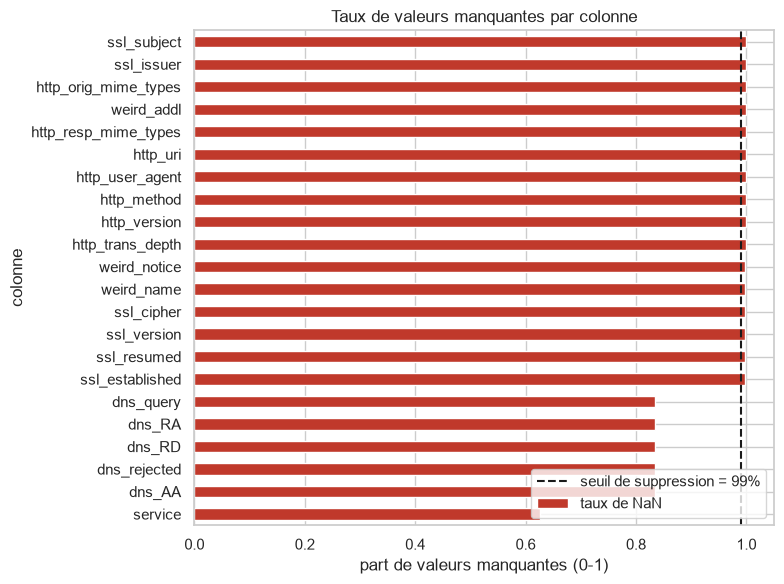

Doublons exacts dans le brut : 20,569 (9.7%)


In [4]:
miss = raw.isna().mean().sort_values(ascending=False)
miss = miss[miss > 0]
print(f"{len(miss)} colonnes avec des valeurs manquantes (après conversion de '-')")
fig, ax = plt.subplots(figsize=(8, 6))
miss.sort_values().plot(kind="barh", ax=ax, color="#c0392b", label="taux de NaN")
ax.axvline(U.MAX_MISSING_RATE, color="k", ls="--", label=f"seuil de suppression = {U.MAX_MISSING_RATE:.0%}")
ax.set(title="Taux de valeurs manquantes par colonne", xlabel="part de valeurs manquantes (0-1)", ylabel="colonne")
ax.legend(loc="lower right"); plt.tight_layout(); U.savefig(fig, "01_missing_rates"); plt.show()
dup_exact = int(raw.duplicated().sum())
print(f"Doublons exacts dans le brut : {dup_exact:,} ({dup_exact / n_raw:.1%})")
report["dup_exact_raw"] = dup_exact

## 2. Vérification de la cible et analyse exploratoire (EDA)

Deux cibles **différentes** : `label` (binaire : 0 normal / 1 attaque) et `type` (10 classes). `label` se déduit entièrement de `type` :
`type` ne doit donc **jamais** être une variable explicative.

label,0,1
type,,
backdoor,0,20000
ddos,0,20000
dos,0,20000
injection,0,20000
mitm,0,1043
normal,50000,0
password,0,20000
ransomware,0,20000
scanning,0,20000


OK : label == (type != 'normal'). `type` est exclu des variables explicatives.
Part des attaques : 76.3% | classe la plus rare (mitm) : 0.49%


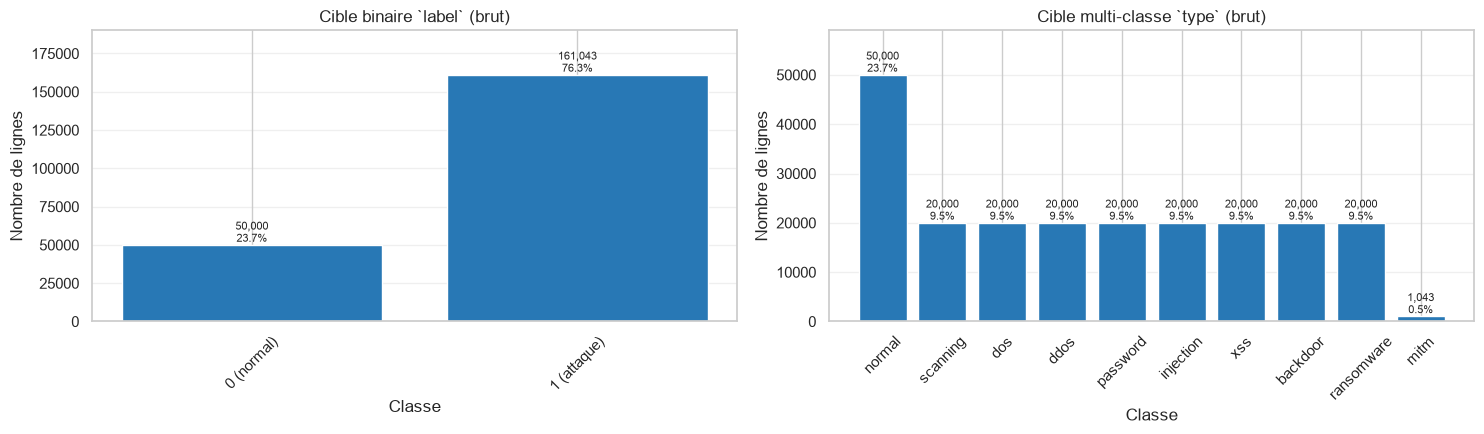

In [5]:
ct = pd.crosstab(raw["type"], raw["label"]); display(ct)
assert (raw["label"].to_numpy() == (raw["type"] != "normal").to_numpy()).all(), "label n'est pas égal à (type != 'normal')"
print("OK : label == (type != 'normal'). `type` est exclu des variables explicatives.")
print(f"Part des attaques : {raw['label'].mean():.1%} | classe la plus rare (mitm) : {(raw['type'] == 'mitm').mean():.2%}")
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
U.plot_class_distribution(raw["label"].map({0: "0 (normal)", 1: "1 (attaque)"}), "Cible binaire `label` (brut)", axes[0])
U.plot_class_distribution(raw["type"], "Cible multi-classe `type` (brut)", axes[1], order=U.DOCUMENTED_TYPE_ORDER)
plt.tight_layout(); U.savefig(fig, "01_targets"); plt.show()

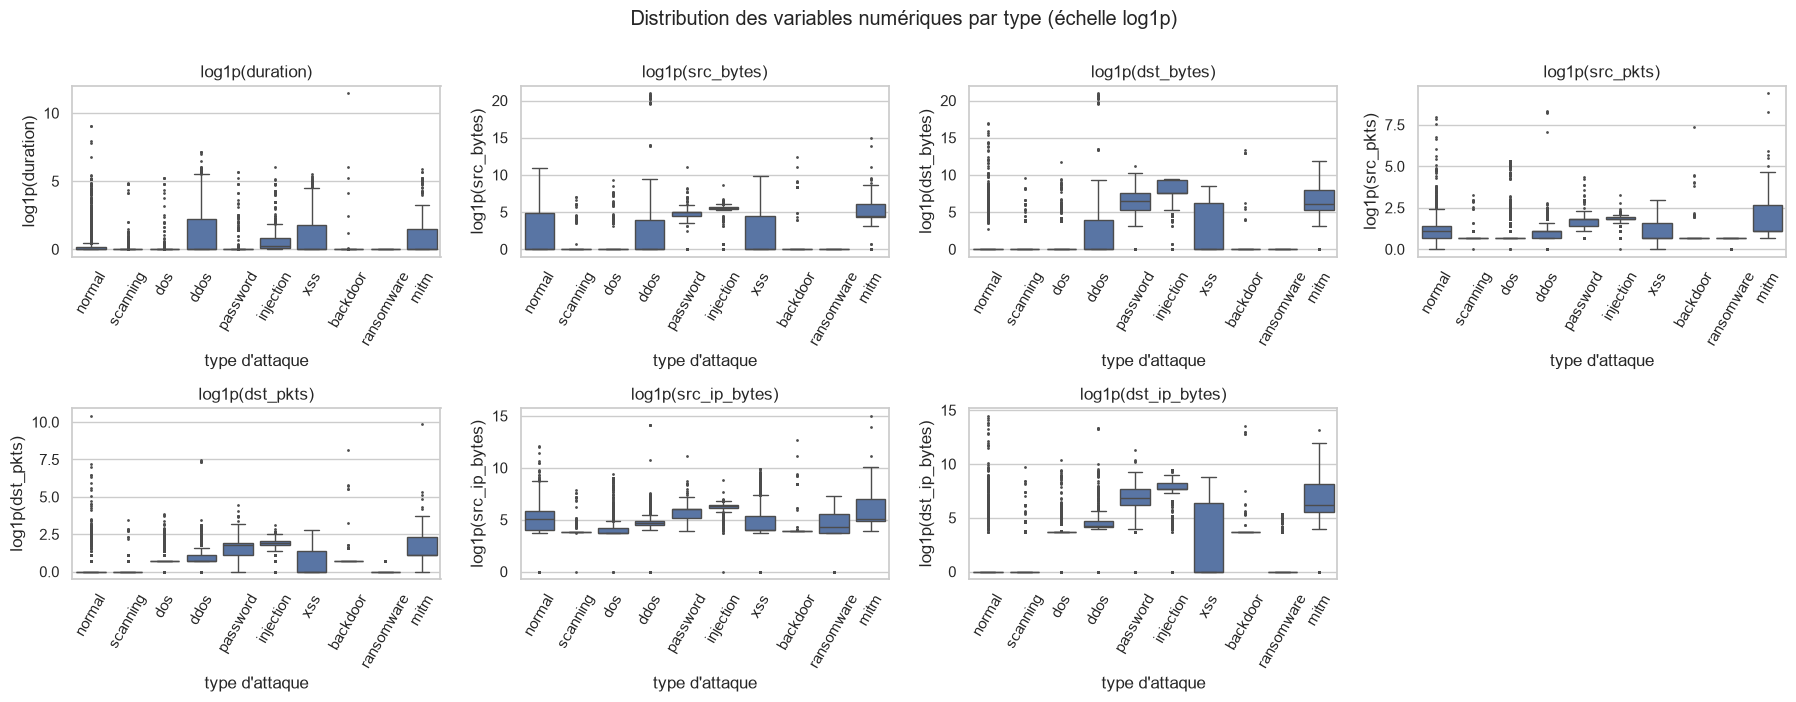

In [6]:
num_eda = ["duration", "src_bytes", "dst_bytes", "src_pkts", "dst_pkts", "src_ip_bytes", "dst_ip_bytes"]
smp = raw.sample(40000, random_state=U.RANDOM_STATE)
fig, axes = plt.subplots(2, 4, figsize=(18, 7)); axes = axes.ravel()
for ax, c in zip(axes, num_eda):
    sns.boxplot(data=smp.assign(v=np.log1p(smp[c])), x="type", y="v", ax=ax, order=U.DOCUMENTED_TYPE_ORDER, fliersize=1)
    ax.set(title=f"log1p({c})", xlabel="type d'attaque", ylabel=f"log1p({c})"); ax.tick_params(axis="x", rotation=60)
axes[-1].axis("off"); fig.suptitle("Distribution des variables numériques par type (échelle log1p)", y=1.0)
plt.tight_layout(); U.savefig(fig, "01_numeric_by_type"); plt.show()

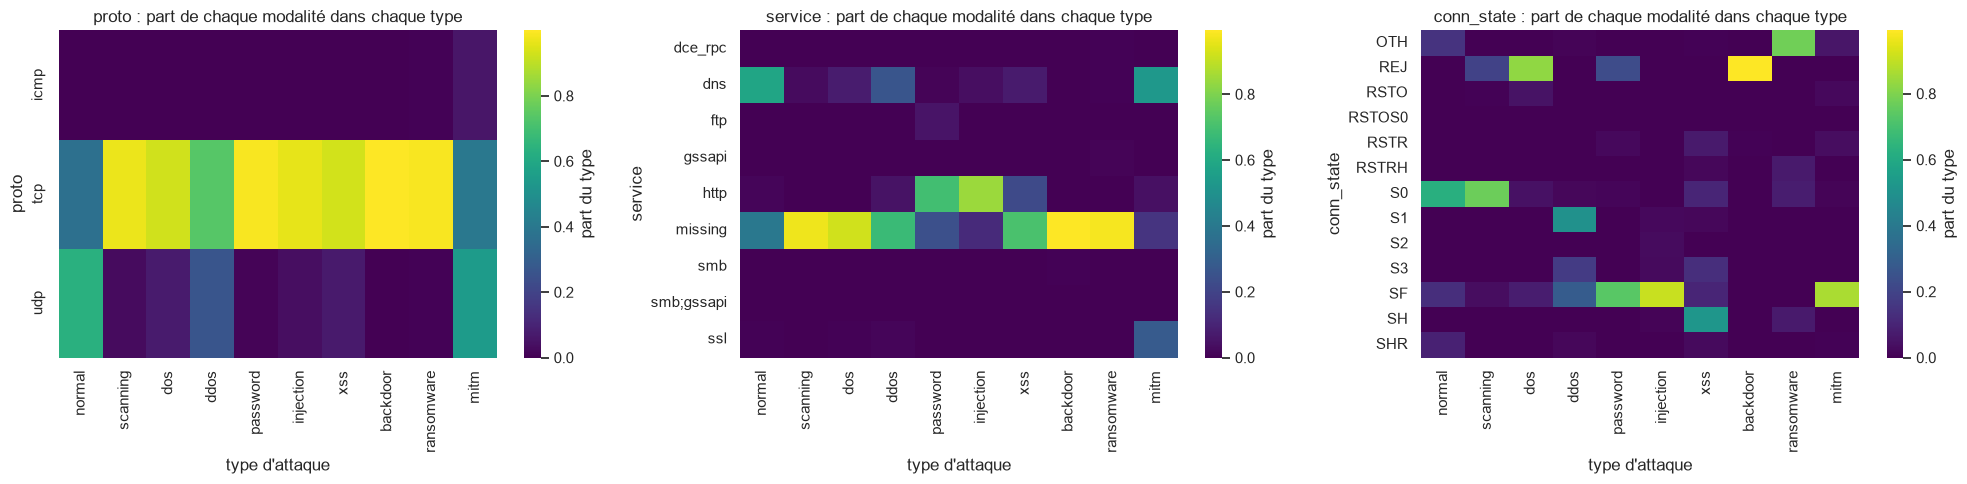

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for ax, c in zip(axes, ["proto", "service", "conn_state"]):
    t = pd.crosstab(raw[c].fillna("missing"), raw["type"])[U.DOCUMENTED_TYPE_ORDER]
    sns.heatmap(t.div(t.sum(axis=0), axis=1), annot=False, cmap="viridis", ax=ax, cbar_kws={"label": "part du type"})
    ax.set(title=f"{c} : part de chaque modalité dans chaque type", xlabel="type d'attaque", ylabel=c)
plt.tight_layout(); U.savefig(fig, "01_categorical_by_type"); plt.show()

## 3. Feature engineering

Variables dérivées **ligne par ligne** (aucune statistique globale, donc aucune fuite) :

- **Indicateurs de protocole** `has_dns / has_http / has_ssl / has_weird` : remplacent les colonnes `http_*`, `ssl_*`, `weird_*`
  presque vides (>99 % de NaN) tout en conservant l'information « ce flux contient du HTTP/SSL/… ».
- **Volumes / débits / ratios** : `total_bytes`, `bytes_ratio`, `bytes_per_sec`, `pkts_per_sec`… (scans et DoS ont des signatures de débit très différentes).
- **Ports en catégories** (`well_known / registered / ephemeral`) plutôt que 65 535 valeurs quasi-ordinales.

**Retiré par rapport à l'ancienne version : `src_internal` / `dst_internal`.** Ces indicateurs (« l'IP commence par 192.168. ») réintroduisaient
le plan d'adressage du banc d'essai, alors que les IP sont volontairement exclues : raccourci topologique qui ne se transfère pas à un autre réseau.

In [8]:
fe = U.engineer_features(raw)
new_cols = [c for c in fe.columns if c not in raw.columns]
assert not {"src_internal", "dst_internal"} & set(fe.columns)
print(f"{len(new_cols)} variables créées :", new_cols)
display(fe[new_cols + ["type"]].groupby("type").median(numeric_only=True).round(3).loc[U.DOCUMENTED_TYPE_ORDER])

17 variables créées : ['has_dns', 'has_http', 'has_ssl', 'has_weird', 'total_bytes', 'total_pkts', 'bytes_ratio', 'pkts_ratio', 'bytes_per_pkt_src', 'bytes_per_pkt_dst', 'bytes_per_sec', 'pkts_per_sec', 'ip_overhead_src', 'ip_overhead_dst', 'src_port_bucket', 'dst_port_bucket', 'same_ports']


,has_dns,has_http,has_ssl,has_weird,total_bytes,total_pkts,bytes_ratio,pkts_ratio,bytes_per_pkt_src,bytes_per_pkt_dst,bytes_per_sec,pkts_per_sec,ip_overhead_src,ip_overhead_dst,same_ports
type,,,,,,,,,,,,,,,
normal,0.0000,0.0000,0.0000,0.0000,122.0000,2.0000,0.0000,2.0000,0.0000,0.0000,88.4440,604.9580,56.0000,0.0000,0.0000
scanning,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,0.0000,0.0000,1000.0000,44.0000,0.0000,0.0000
dos,0.0000,0.0000,0.0000,0.0000,0.0000,2.0000,0.0000,0.5000,0.0000,0.0000,0.0000,1752.8480,40.0000,40.0000,1.0000
ddos,0.0000,0.0000,0.0000,0.0000,0.0000,3.0000,0.0000,1.0000,0.0000,0.0000,0.0000,907.3340,112.0000,60.0000,0.0000
password,0.0000,0.0000,0.0000,0.0000,806.0000,10.0000,0.0800,0.8330,25.5000,108.5000,99793.0160,1821.4940,268.0000,268.0000,0.0000
injection,0.0000,0.0000,0.0000,0.0000,2492.0000,11.0000,0.0920,0.7140,41.5000,356.5710,9854.9980,39.4160,268.0000,320.0000,0.0000
xss,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,0.0000,0.0000,1000.0000,52.0000,0.0000,0.0000
backdoor,0.0000,0.0000,0.0000,0.0000,0.0000,2.0000,0.0000,0.5000,0.0000,0.0000,0.0000,1768.3470,48.0000,40.0000,0.0000
ransomware,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,0.0000,0.0000,1000.0000,76.0000,0.0000,0.0000


## 4. Nettoyage

### 4.1 Colonnes écartées *sans regarder la cible*

| Règle | Raison |
|---|---|
| `src_ip`, `dst_ip` | identifiants d'hôtes : le modèle mémoriserait l'environnement du banc d'essai |
| **`src_port`** | port source éphémère : rend chaque flux unique (mesuré sur l'ancienne version : **43,5 %** des lignes de test avaient un quasi-doublon dans le train ne différant que par ce port), aucune valeur sémantique ; la catégorie `src_port_bucket` est conservée |
| `label`, `type` hors cible | fuite directe |
| > 99 % de NaN | aucune information exploitable (les `has_*` conservent le signal) |
| texte à cardinalité > 50 | one-hot ingérable et mémorisation (`dns_query`, `http_uri`, …) |

Toutes ces règles sont **indépendantes de la cible** : les appliquer avant le split ne fuit rien.

In [9]:
drop_reason = dict(U.LEAKY_OR_ID_COLUMNS)
for c in fe.columns:
    if c not in drop_reason and fe[c].isna().mean() > U.MAX_MISSING_RATE:
        drop_reason[c] = f"> {U.MAX_MISSING_RATE:.0%} de valeurs manquantes"
text_cols = [c for c in fe.columns if not pd.api.types.is_numeric_dtype(fe[c]) and c != "type" and c not in drop_reason]
for c in text_cols:
    if fe[c].nunique() > 50:
        drop_reason[c] = f"cardinalité élevée ({fe[c].nunique()} modalités)"
display(pd.Series(drop_reason, name="raison").to_frame())
clean = fe.drop(columns=list(drop_reason))
cand_cols = [c for c in clean.columns if c not in ("label", "type")]
print(f"{len(cand_cols)} variables candidates :", cand_cols)

,raison
src_ip,identifiant d'hôte : mémorisation de l'environ...
dst_ip,identifiant d'hôte : mémorisation de l'environ...
src_port,"port source éphémère : rend les flux uniques, ..."
ssl_version,> 99% de valeurs manquantes
ssl_cipher,> 99% de valeurs manquantes
ssl_resumed,> 99% de valeurs manquantes
ssl_established,> 99% de valeurs manquantes
ssl_subject,> 99% de valeurs manquantes
ssl_issuer,> 99% de valeurs manquantes
http_trans_depth,> 99% de valeurs manquantes


39 variables candidates : ['dst_port', 'proto', 'service', 'duration', 'src_bytes', 'dst_bytes', 'conn_state', 'missed_bytes', 'src_pkts', 'src_ip_bytes', 'dst_pkts', 'dst_ip_bytes', 'dns_qclass', 'dns_qtype', 'dns_rcode', 'dns_AA', 'dns_RD', 'dns_RA', 'dns_rejected', 'http_request_body_len', 'http_response_body_len', 'http_status_code', 'has_dns', 'has_http', 'has_ssl', 'has_weird', 'total_bytes', 'total_pkts', 'bytes_ratio', 'pkts_ratio', 'bytes_per_pkt_src', 'bytes_per_pkt_dst', 'bytes_per_sec', 'pkts_per_sec', 'ip_overhead_src', 'ip_overhead_dst', 'src_port_bucket', 'dst_port_bucket', 'same_ports']


### 4.2 Déduplication dans l'espace des variables candidates — **avant** le split

Les lignes identiques sont très nombreuses (flux répétitifs). Si on les laisse, une même ligne tombe à la fois dans le *train* et dans le *test*
et les scores sont **gonflés** par mémorisation. Étapes :

1. suppression des doublons exacts (variables candidates + `label` + `type`) ;
2. suppression des **conflits** : mêmes variables candidates mais types différents, par nature indécidables pour n'importe quel modèle.

Cette déduplication est faite **sur les variables candidates, déjà privées de `src_port`**. Une passe finale dans l'espace *final* (après sélection) est faite en §7.

In [10]:
stage = {"brut": raw["type"].value_counts()}
n0 = len(clean)
clean = clean.drop_duplicates().reset_index(drop=True)
n1 = len(clean)
stage["après doublons exacts"] = clean["type"].value_counts()
h = pd.util.hash_pandas_object(clean[cand_cols], index=False)
conflict = (clean.assign(_h=h).groupby("_h")["type"].transform("nunique") > 1).to_numpy()
n_conf = int(conflict.sum())
clean = clean.loc[~conflict].reset_index(drop=True)
stage["après conflits"] = clean["type"].value_counts()
print(f"Lignes brutes                 : {n_raw:,}")
print(f"Doublons exacts supprimés     : {n0 - n1:,}  ->  {n1:,}")
print(f"Lignes en conflit supprimées  : {n_conf:,}  ->  {len(clean):,}")
print(f"Lignes conservées             : {len(clean):,} ({len(clean) / n_raw:.1%} du brut)")
stage_df = pd.DataFrame(stage).loc[U.DOCUMENTED_TYPE_ORDER]
display(stage_df)
report.update(n_rows_after_exact_dedup=int(n1), n_dup_removed_candidate_space=int(n0 - n1), n_conflicts=n_conf,
              n_rows_clean=len(clean), dedup_by_type=stage_df.to_dict("index"))

Lignes brutes                 : 211,043
Doublons exacts supprimés     : 102,407  ->  108,636
Lignes en conflit supprimées  : 290  ->  108,346
Lignes conservées             : 108,346 (51.3% du brut)


,brut,après doublons exacts,après conflits
type,,,
normal,50000,25213,25204
scanning,20000,6051,6045
dos,20000,14531,14522
ddos,20000,13376,13283
password,20000,16080,16079
injection,20000,19885,19786
xss,20000,8803,8734
backdoor,20000,2423,2423
ransomware,20000,1235,1233


### 4.3 Valeurs aberrantes (outliers)

Les volumes d'octets/paquets ont des **queues très lourdes** (max ≈ 4·10⁹ octets pour une médiane proche de 0). En réseau, ces valeurs extrêmes
**sont le signal** (DoS, exfiltration, scans) : les supprimer retirerait précisément les attaques. **Décision : aucune ligne supprimée**
(pas de règle IQR) ; on applique `log1p` aux variables très asymétriques (skew élevé) **dans le pipeline** — transformation sans paramètre appris, donc sans fuite.
Indispensable pour le SVM (distances), neutre pour les arbres.

,asymétrie (skew),% hors IQR x1.5,log1p appliqué
dst_ip_bytes,318.6260,11.0092,True
http_response_body_len,292.1795,0.2474,True
bytes_per_sec,231.2017,17.1801,True
bytes_ratio,219.4886,15.0379,True
dst_pkts,208.6058,6.8087,True
missed_bytes,181.0690,2.7172,True
total_pkts,180.8034,11.9035,True
pkts_ratio,175.3834,17.2955,True
http_request_body_len,123.0277,0.0148,True
src_ip_bytes,118.7935,15.5391,True


Variables très asymétriques (skew > 5) sans log1p : ['http_status_code', 'has_http', 'has_weird', 'has_ssl', 'dns_qtype', 'dns_qclass', 'dst_port']


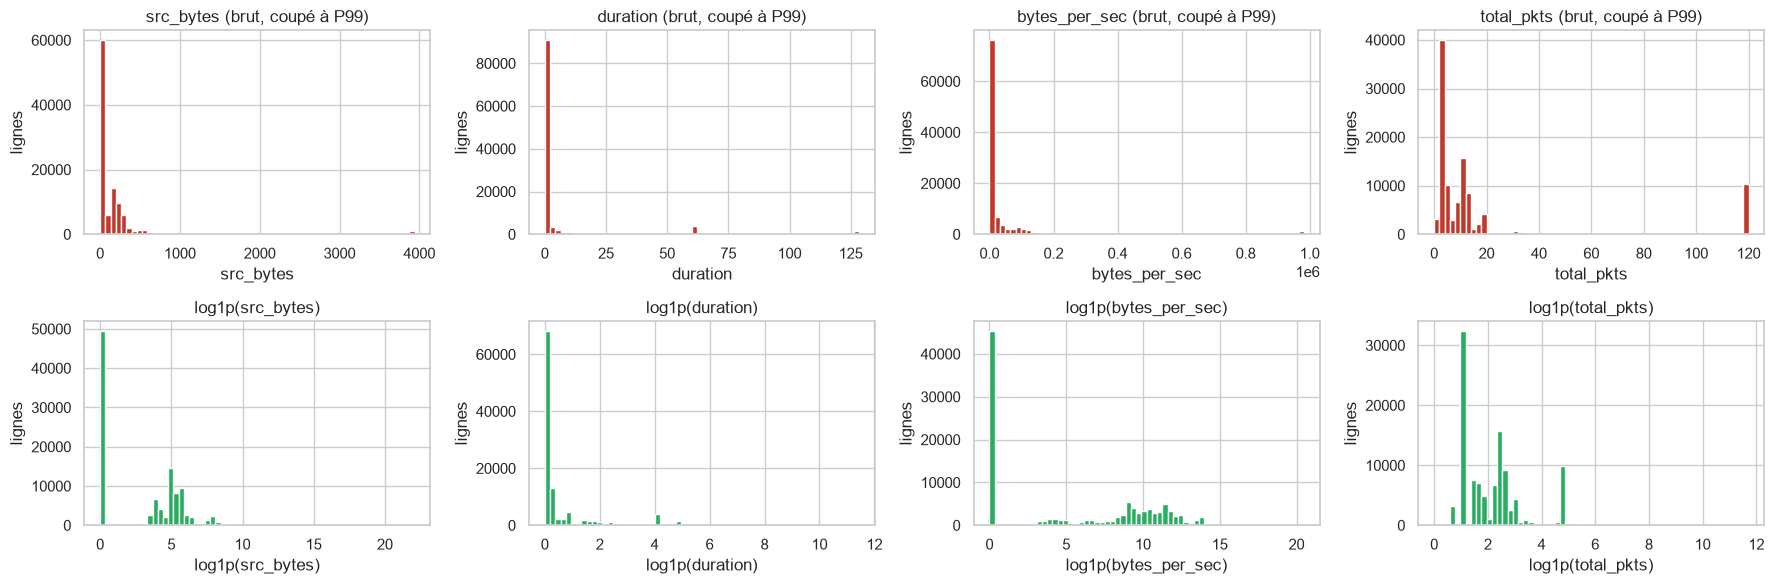

In [11]:
num_now = [c for c in clean.select_dtypes(include="number").columns if c != "label"]
q1, q3 = clean[num_now].quantile(.25), clean[num_now].quantile(.75); iqr = q3 - q1
stats = pd.DataFrame({
    "asymétrie (skew)": clean[num_now].skew(),
    "% hors IQR x1.5": ((clean[num_now].lt(q1 - 1.5 * iqr)) | (clean[num_now].gt(q3 + 1.5 * iqr))).mean() * 100,
    "log1p appliqué": [c in U.LOG_COLUMNS for c in num_now],
}).sort_values("asymétrie (skew)", ascending=False)
display(stats.head(15))
print("Variables très asymétriques (skew > 5) sans log1p :", stats[(stats["asymétrie (skew)"] > 5) & ~stats["log1p appliqué"]].index.tolist())
fig, axes = plt.subplots(2, 4, figsize=(18, 6))
for j, c in enumerate(["src_bytes", "duration", "bytes_per_sec", "total_pkts"]):
    v = clean[c]
    axes[0, j].hist(v.clip(upper=v.quantile(.99)), bins=60, color="#c0392b"); axes[0, j].set(title=f"{c} (brut, coupé à P99)", xlabel=c, ylabel="lignes")
    axes[1, j].hist(np.log1p(v), bins=60, color="#27ae60"); axes[1, j].set(title=f"log1p({c})", xlabel=f"log1p({c})", ylabel="lignes")
plt.tight_layout(); U.savefig(fig, "01_outliers_log1p"); plt.show()

## 5. Split stratifié 60 / 20 / 20

Le découpage est fait **avant** toute sélection de variables ou apprentissage. La stratification sur `type` garantit que la classe rare `mitm`
est présente dans chaque jeu (et que `label`, qui dérive de `type`, est aussi stratifié).
- **Train (60 %)** : apprentissage, validation croisée, rééchantillonnage
- **Validation (20 %)** : choix des hyper-paramètres, du **seuil**, du calibrateur, des seuils de décodage
- **Test (20 %)** : lu **une seule fois**, à la fin de chaque notebook de modélisation

Les tailles seront légèrement inférieures à 60/20/20 après la déduplication inter-splits du §7.

In [12]:
from sklearn.model_selection import train_test_split
y_all = clean[["label", "type"]].copy()
X_all = clean.drop(columns=["label", "type"])
X_tmp, X_test, y_tmp, y_test = train_test_split(X_all, y_all, test_size=0.20, stratify=y_all["type"], random_state=U.RANDOM_STATE)
X_train, X_valid, y_train, y_valid = train_test_split(X_tmp, y_tmp, test_size=0.25, stratify=y_tmp["type"], random_state=U.RANDOM_STATE)
for d in (X_train, X_valid, X_test, y_train, y_valid, y_test): d.reset_index(drop=True, inplace=True)
print({n: len(y) for n, y in [("train", y_train), ("valid", y_valid), ("test", y_test)]})
report["split_sizes_initial"] = {"train": len(X_train), "valid": len(X_valid), "test": len(X_test)}

{'train': 65007, 'valid': 21669, 'test': 21670}


## 6. Sélection de variables (calculée sur le train uniquement)

Méthodes **filtre** en trois étapes :
1. variance nulle (constantes) ;
2. **corrélation de Spearman** : parmi deux variables numériques de |ρ| > 0,97, on supprime la dérivée (redondance, instabilité du SVM) ;
3. **information mutuelle** avec chaque cible : on supprime les variables sans lien avec **aucune** des deux cibles.

La sélection **embarquée** (importances Random Forest / XGBoost, permutation) est faite dans les notebooks 02 à 05.

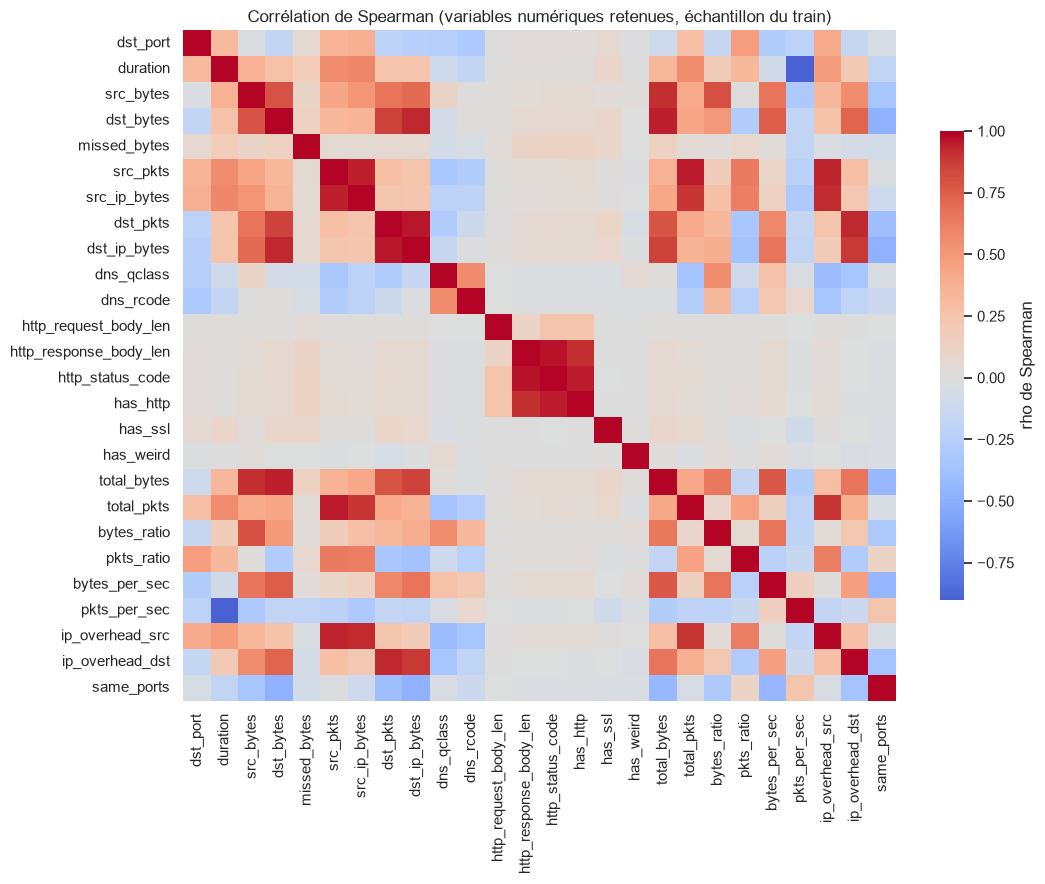

,raison
dns_qtype,corrélée à dns_qclass (|rho|=0.996)
has_dns,corrélée à dns_qclass (|rho|=0.997)
bytes_per_pkt_src,corrélée à src_bytes (|rho|=0.979)
bytes_per_pkt_dst,corrélée à dst_bytes (|rho|=0.993)


In [13]:
num_cols, cat_cols = U.split_columns(X_train)
removed = {}
for c in X_train.columns:
    if X_train[c].nunique(dropna=False) <= 1: removed[c] = "constante sur le train"
num_cols = [c for c in num_cols if c not in removed]; cat_cols = [c for c in cat_cols if c not in removed]
smp = X_train[num_cols].sample(min(50000, len(X_train)), random_state=U.RANDOM_STATE)
corr = smp.corr(method="spearman").abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
for c in upper.columns:
    partners = upper.index[upper[c] > 0.97].tolist()
    if partners and c not in removed: removed[c] = f"corrélée à {partners[0]} (|rho|={upper.loc[partners[0], c]:.3f})"
num_cols = [c for c in num_cols if c not in removed]
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(smp[num_cols].corr(method="spearman"), cmap="coolwarm", center=0, ax=ax, cbar_kws={"shrink": .7, "label": "rho de Spearman"})
ax.set_title("Corrélation de Spearman (variables numériques retenues, échantillon du train)"); plt.tight_layout(); U.savefig(fig, "01_correlation"); plt.show()
display(pd.Series(removed, name="raison").to_frame())

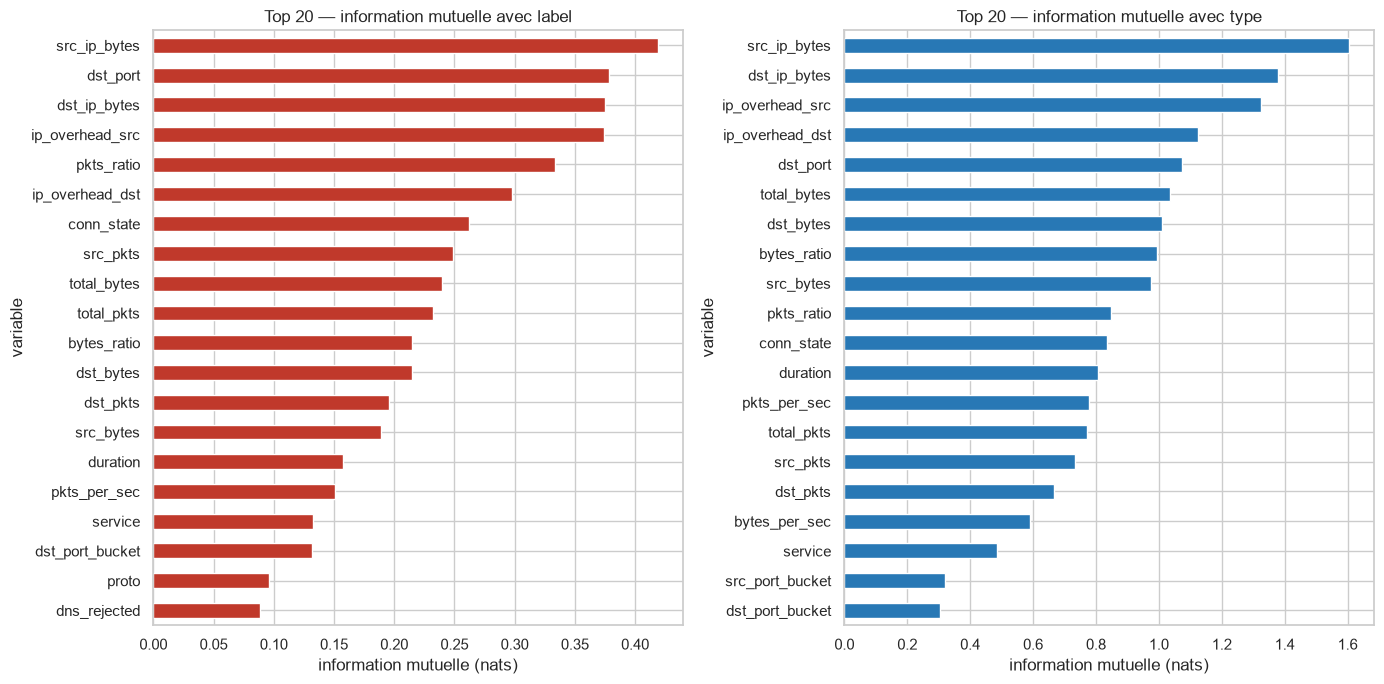

Variables retenues : 26 numériques + 9 catégorielles = 35
Supprimées par MI : []


In [14]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import OrdinalEncoder
idx = X_train.sample(min(30000, len(X_train)), random_state=U.RANDOM_STATE).index
Xm = X_train.loc[idx, num_cols + cat_cols].copy()
Xm[num_cols] = Xm[num_cols].fillna(Xm[num_cols].median())
Xm[cat_cols] = OrdinalEncoder().fit_transform(Xm[cat_cols].fillna("missing"))
disc = np.array([c in cat_cols for c in Xm.columns])
mi = pd.DataFrame({
    "MI_label": mutual_info_classif(Xm, y_train.loc[idx, "label"], discrete_features=disc, random_state=U.RANDOM_STATE),
    "MI_type": mutual_info_classif(Xm, y_train.loc[idx, "type"], discrete_features=disc, random_state=U.RANDOM_STATE),
}, index=Xm.columns).sort_values("MI_type", ascending=False)
low = mi[(mi.MI_label < 0.001) & (mi.MI_type < 0.001)].index.tolist()
for c in low: removed[c] = "information mutuelle ~ 0 avec label ET type"
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, col, color in zip(axes, ["MI_label", "MI_type"], ["#c0392b", "#2878b5"]):
    mi[col].sort_values().tail(20).plot(kind="barh", ax=ax, color=color)
    ax.set(title=f"Top 20 — information mutuelle avec {col[3:]}", xlabel="information mutuelle (nats)", ylabel="variable")
plt.tight_layout(); U.savefig(fig, "01_mutual_information"); plt.show()
num_cols = [c for c in num_cols if c not in low]; cat_cols = [c for c in cat_cols if c not in low]
keep = num_cols + cat_cols
print(f"Variables retenues : {len(num_cols)} numériques + {len(cat_cols)} catégorielles = {len(keep)}")
print("Supprimées par MI :", low)

## 7. Déduplication inter-splits dans l'espace **final** des variables

C'est le correctif central. La sélection de variables retire des colonnes : deux lignes qui différaient seulement par une colonne retirée
deviennent **identiques** dans l'espace réellement vu par les modèles. Si l'une est dans le train et l'autre dans le test, le modèle la « connaît ».
On mesure donc le recouvrement **dans l'espace final**, puis on retire :
- les lignes de la **validation** présentes dans le train ;
- les lignes du **test** présentes dans le train ∪ validation.

Le train n'est jamais réduit ; l'assertion finale exige un recouvrement **nul**.

In [15]:
def overlaps(Xtr, Xva, Xte):
    return pd.Series({"valid ∩ train": U.cross_split_overlap(Xtr, Xva),
                      "test ∩ train": U.cross_split_overlap(Xtr, Xte),
                      "test ∩ (train ∪ valid)": U.cross_split_overlap(pd.concat([Xtr, Xva]), Xte)}) * 100

Xtr, Xva, Xte = X_train[keep], X_valid[keep], X_test[keep]
ov_before = overlaps(Xtr, Xva, Xte)
types_before = {n: y["type"].value_counts() for n, y in [("train", y_train), ("valid", y_valid), ("test", y_test)]}
print(f"Doublons INTERNES au train dans l'espace final : {Xtr.duplicated().mean():.1%} (information, non supprimés : ils ne fuient pas)")

X_valid, y_valid, n_drop_valid = U.drop_rows_present_in(Xtr, Xva, y_valid)
X_test, y_test, n_drop_test = U.drop_rows_present_in(pd.concat([Xtr, X_valid]), Xte, y_test)
X_train = Xtr
ov_after = overlaps(X_train, X_valid, X_test)
display(pd.DataFrame({"avant (%)": ov_before, "après (%)": ov_after}).round(3))
assert (ov_after == 0).all(), "recouvrement résiduel entre splits"
print(f"Lignes retirées : validation {n_drop_valid:,} | test {n_drop_test:,}")
print(f"Tailles finales : train {len(X_train):,} | valid {len(X_valid):,} | test {len(X_test):,}")
for n, y in [("valid", y_valid), ("test", y_test)]:
    assert (y["label"].to_numpy() == (y["type"] != "normal").to_numpy()).all()
types_after = {"train": y_train["type"].value_counts(), "valid": y_valid["type"].value_counts(), "test": y_test["type"].value_counts()}
by_type = pd.concat({**{f"avant {k}": s for k, s in types_before.items()}, **{f"après {k}": s for k, s in types_after.items()}}, axis=1).loc[U.DOCUMENTED_TYPE_ORDER]
display(by_type)
report.update(overlap_before_pct=ov_before.round(4).to_dict(), overlap_after_pct=ov_after.to_dict(),
              n_dropped_valid_cross_split=n_drop_valid, n_dropped_test_cross_split=n_drop_test,
              split_sizes={"train": len(X_train), "valid": len(X_valid), "test": len(X_test)},
              counts_by_type_before_after_cross_split=by_type.to_dict("index"))

Doublons INTERNES au train dans l'espace final : 0.4% (information, non supprimés : ils ne fuient pas)


,avant (%),après (%)
valid ∩ train,0.8630,0.0000
test ∩ train,0.8350,0.0000
test ∩ (train ∪ valid),1.0710,0.0000


Lignes retirées : validation 187 | test 232
Tailles finales : train 65,007 | valid 21,482 | test 21,438


,avant train,avant valid,avant test,après train,après valid,après test
type,,,,,,
normal,15122,5041,5041,15122,4910,4866
scanning,3627,1209,1209,3627,1191,1187
dos,8714,2904,2904,8714,2878,2882
ddos,7970,2656,2657,7970,2655,2657
password,9647,3216,3216,9647,3213,3215
injection,11872,3957,3957,11872,3956,3956
xss,5240,1747,1747,5240,1745,1745
backdoor,1453,485,485,1453,485,485
ransomware,740,246,247,740,246,247


## 8. Distribution des classes par split et aperçu de l'équilibrage

Deux déséquilibres distincts :
- **Binaire** : la classe *normal* est minoritaire (~20-25 %). Le déséquilibre est **inversé** par rapport à un cas classique, et ce sont justement les erreurs sur « normal » (faux positifs) qui créent des fausses alertes.
- **Multi-classe** : `mitm` ≈ 1 % des lignes, très en dessous des autres attaques.

**Règle d'or.** Le rééchantillonnage (ROS, SMOTE, SMOTENC) ne s'applique **qu'au train**, **après** le split, et **dans** un `Pipeline` imbalanced-learn
pour n'être appliqué qu'aux plis d'apprentissage de la validation croisée. Validation et test gardent la distribution réelle.
SMOTENC est nécessaire dès qu'il y a des variables catégorielles : SMOTE interpole sur du one-hot et fabrique des points impossibles.
Les notebooks 02-05 comparent les stratégies par **validation croisée** (règle de parcimonie) ; ici on ne regarde que les effectifs, sans modèle.

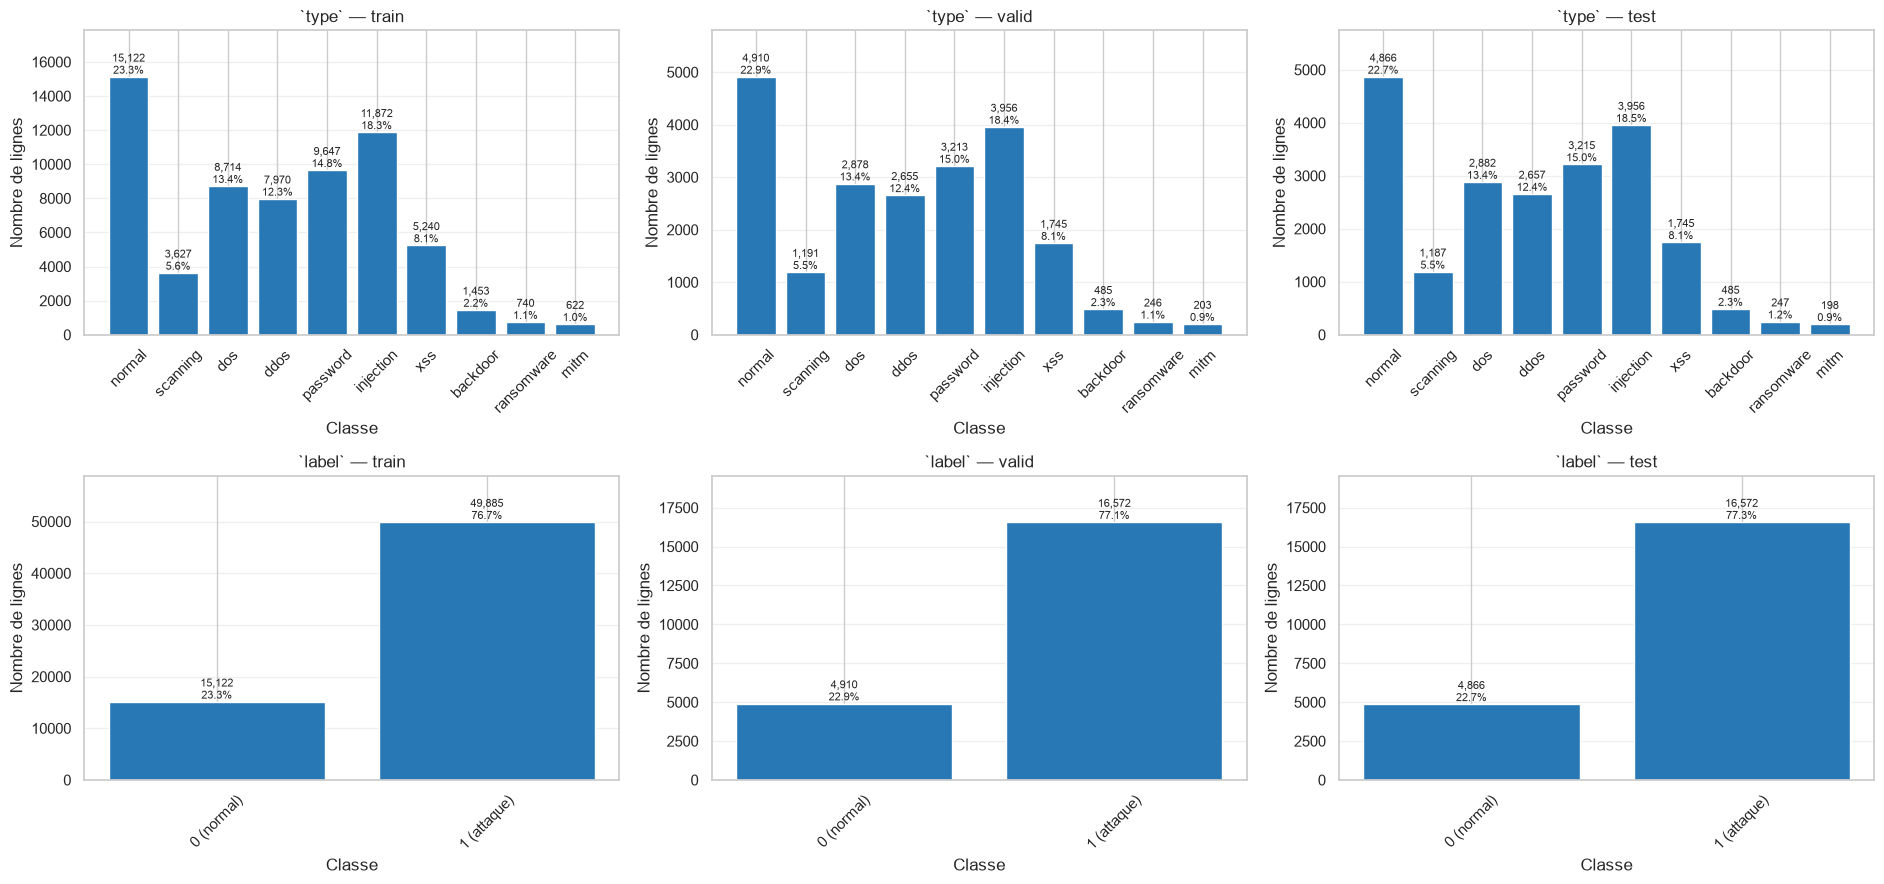

Part d'attaques (label=1) : {'train': 0.7674, 'valid': 0.7714, 'test': 0.773}


In [16]:
fig, axes = plt.subplots(2, 3, figsize=(19, 9))
for j, (n, y) in enumerate([("train", y_train), ("valid", y_valid), ("test", y_test)]):
    U.plot_class_distribution(y["type"], f"`type` — {n}", axes[0, j], order=U.DOCUMENTED_TYPE_ORDER)
    U.plot_class_distribution(y["label"].map({0: "0 (normal)", 1: "1 (attaque)"}), f"`label` — {n}", axes[1, j])
plt.tight_layout(); U.savefig(fig, "01_class_distribution_splits"); plt.show()
print("Part d'attaques (label=1) :", {n: round(float(y["label"].mean()), 4) for n, y in [("train", y_train), ("valid", y_valid), ("test", y_test)]})

Aperçu calculé en 17 s (sous-échantillon stratifié de 30 000 lignes du train)


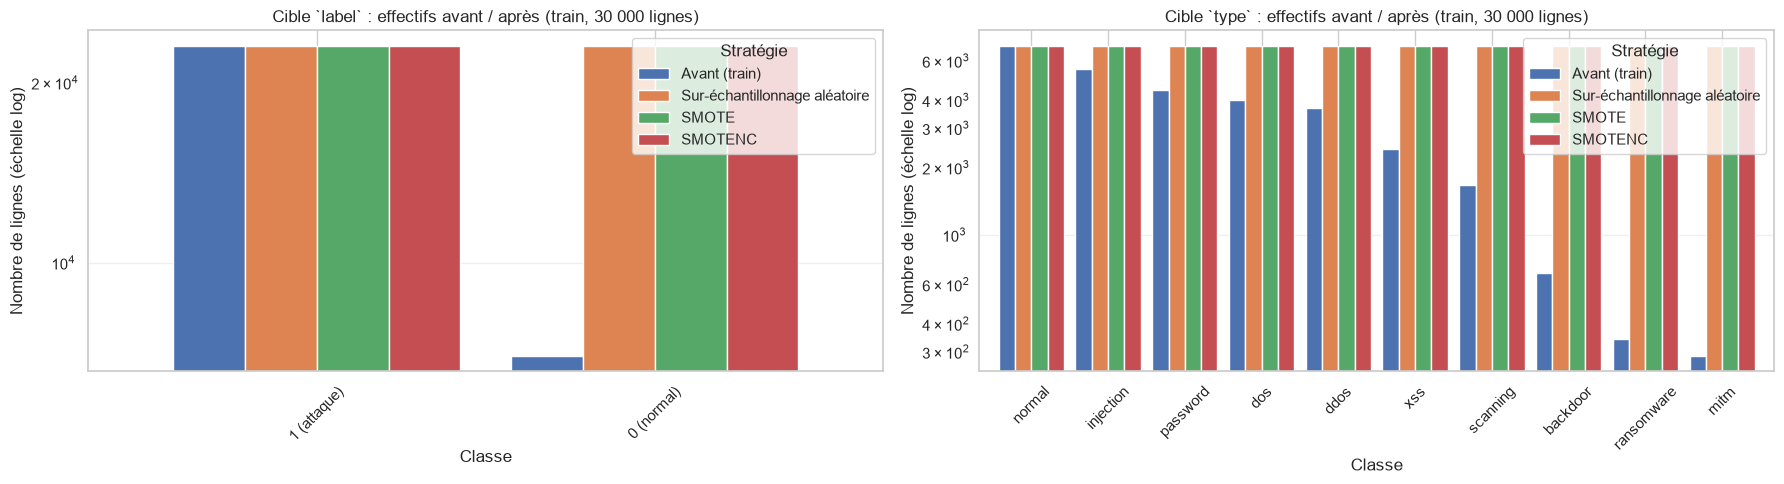

avant  Sur-échantillonnage aléatoire  SMOTE  SMOTENC
label 1           23021                          23021  23021    23021
      0            6979                          23021  23021    23021
type  backdoor      671                           6979   6979     6979
      ddos         3678                           6979   6979     6979
      dos          4021                           6979   6979     6979
      injection    5479                           6979   6979     6979
      mitm          287                           6979   6979     6979
      normal       6979                           6979   6979     6979
      password     4452                           6979   6979     6979
      ransomware    341                           6979   6979     6979
      scanning     1674                           6979   6979     6979
      xss          2418                           6979   6979     6979

In [17]:
from sklearn.ensemble import RandomForestClassifier  # estimateur factice : jamais entraîné ici

def resample_counts(strategy, target, n=30000):
    idx = train_test_split(np.arange(len(X_train)), train_size=n, stratify=y_train["type"], random_state=U.RANDOM_STATE)[0]
    Xs, ys = X_train.iloc[idx], y_train[target].iloc[idx]
    pipe = U.make_model_pipeline(RandomForestClassifier(), num_cols, cat_cols, strategy)
    k = [name for name, _ in pipe.steps].index("sampler")
    _, yr = pipe[:k + 1].fit_resample(Xs, ys)
    return ys, pd.Series(np.asarray(yr), name=target)

balance, t0 = {}, time.time()
for target in ("label", "type"):
    for strat in ("ros", "smote", "smotenc"):
        balance[(target, strat)] = resample_counts(strat, target)
print(f"Aperçu calculé en {time.time() - t0:.0f} s (sous-échantillon stratifié de 30 000 lignes du train)")
names01 = {0: "0 (normal)", 1: "1 (attaque)"}
fig, axes = plt.subplots(1, 2, figsize=(18, 5))
for ax, target in zip(axes, ("label", "type")):
    before = balance[(target, "ros")][0]
    after = {U.STRATEGY_LABELS[s]: balance[(target, s)][1] for s in ("ros", "smote", "smotenc")}
    if target == "label":
        before = before.map(names01); after = {k: v.map(names01) for k, v in after.items()}
    U.plot_balancing_effect(before, after, ax=ax); ax.set_title(f"Cible `{target}` : effectifs avant / après (train, 30 000 lignes)")
plt.tight_layout(); U.savefig(fig, "01_balancing_effect"); plt.show()
table = pd.concat({t: pd.DataFrame({"avant": balance[(t, "ros")][0].value_counts(), **{U.STRATEGY_LABELS[s]: balance[(t, s)][1].value_counts() for s in ("ros", "smote", "smotenc")}}) for t in ("label", "type")})
display(table)
report["balancing_preview_counts"] = {f"{t}/{c}": r.to_dict() for (t, c), r in table.iterrows()}

## 9. Étude de l'encodage ordinal de `type` (régresseurs 04 et 05)

Le sujet impose des **régresseurs** pour prédire `type`. Or `type` est une variable **nominale** : donner à `mitm` le code 9 et à `dos` le code 2
signifie, pour un régresseur, que `mitm` est « plus grand » que `dos`, et qu'une prédiction de 5,5 est « entre » `injection` et `xss`.
L'ordre est donc un **artefact** de modélisation ; un mauvais ordre rend la tâche plus difficile (classes proches dans l'espace des codes
mais éloignées dans l'espace des variables). Dans l'ancienne version, un ordre *aléatoire* battait l'ordre « documenté » (RMSE 0,369 vs 0,448 ; F1 macro 0,907 vs 0,882) :
l'argument « codes proches = comportements proches » n'était pas soutenu par les données.

**Protocole** (train uniquement, 30 000 lignes, validation croisée à 3 plis, `RandomForestRegressor` léger, préprocesseur refait dans chaque pli) :

| Candidat | Construction |
|---|---|
| documenté | `DOCUMENTED_TYPE_ORDER` (normal, scanning, dos, ddos, password, injection, xss, backdoor, ransomware, mitm) |
| alphabétique | ordre alphabétique des noms |
| aléatoire ×5 | 5 permutations tirées au hasard (moyenne ± écart-type **entre permutations**) |
| piloté par les données | LDA ajustée sur le train préprocessé ; classes triées par la moyenne de la **1re composante discriminante**. Recalculé **dans chaque pli** (sur son train seulement) pour ne pas fuir vers le pli de validation |

Métrique : **F1 macro après arrondi** au code le plus proche (invariant au choix des codes) et RMSE (indicatif : l'échelle dépend de l'ordre).

**Règle de décision (fixée avant de regarder les résultats)** : on retient l'ordre piloté par les données si son F1 macro CV dépasse celui de l'ordre
documenté de **plus que l'écart-type des permutations aléatoires** (c.-à-d. si la différence dépasse ce que le simple hasard de l'ordre produit) ; sinon on garde l'ordre documenté.

In [18]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedKFold

def dense(a): return a.toarray() if hasattr(a, "toarray") else np.asarray(a)

def data_driven_order(P, types):
    lda = LinearDiscriminantAnalysis(solver="svd").fit(P, types)
    comp1 = pd.Series(lda.transform(P)[:, 0]).groupby(np.asarray(types)).mean().sort_values()
    return comp1.index.tolist()

types_all = sorted(y_train["type"].unique())
n_cls = len(types_all)
rng = np.random.default_rng(U.RANDOM_STATE)
random_orders = {f"aléatoire {i + 1}": [str(t) for t in rng.permutation(types_all)] for i in range(5)}
fixed_orders = {"documenté": U.DOCUMENTED_TYPE_ORDER, "alphabétique": types_all, **random_orders}

sub = train_test_split(np.arange(len(X_train)), train_size=30000, stratify=y_train["type"], random_state=U.RANDOM_STATE)[0]
Xs, ts = X_train.iloc[sub].reset_index(drop=True), y_train["type"].iloc[sub].to_numpy()
rows, t0 = [], time.time()
for fold, (tr, va) in enumerate(StratifiedKFold(3, shuffle=True, random_state=U.RANDOM_STATE).split(Xs, ts)):
    pre = U.make_preprocessor(num_cols, cat_cols, scale=False)
    Ptr, Pva = dense(pre.fit_transform(Xs.iloc[tr])), dense(pre.transform(Xs.iloc[va]))
    for name, order in {**fixed_orders, "piloté par les données": data_driven_order(Ptr, ts[tr])}.items():
        to_code = {t: i for i, t in enumerate(order)}
        ytr, yva = pd.Series(ts[tr]).map(to_code).to_numpy(), pd.Series(ts[va]).map(to_code).to_numpy()
        pred = RandomForestRegressor(n_estimators=60, min_samples_leaf=2, n_jobs=-1, random_state=U.RANDOM_STATE).fit(Ptr, ytr).predict(Pva)
        rows.append({"ordre": name, "pli": fold, "f1_macro": f1_score(yva, U.decode_round(pred, n_cls), average="macro"),
                     "rmse": U.regression_metrics(yva, pred)["rmse"]})
cv = pd.DataFrame(rows)
print(f"Étude réalisée en {time.time() - t0:.0f} s")
per = cv.groupby("ordre")[["f1_macro", "rmse"]].mean()
rand = per.loc[list(random_orders)]
summary = pd.DataFrame({
    "f1_macro": [per.loc["documenté", "f1_macro"], per.loc["alphabétique", "f1_macro"], rand["f1_macro"].mean(), per.loc["piloté par les données", "f1_macro"]],
    "f1_macro_std": [cv[cv.ordre == "documenté"].f1_macro.std(), cv[cv.ordre == "alphabétique"].f1_macro.std(), rand["f1_macro"].std(), cv[cv.ordre == "piloté par les données"].f1_macro.std()],
    "rmse": [per.loc["documenté", "rmse"], per.loc["alphabétique", "rmse"], rand["rmse"].mean(), per.loc["piloté par les données", "rmse"]],
}, index=["documenté", "alphabétique", "aléatoire (moy. 5 perm.)", "piloté par les données"])
summary.index.name = "ordre"
print("Détail par ordre (moyenne des 3 plis) :"); display(per.round(4))
print("Résumé (écart-type : entre plis ; pour « aléatoire » : entre les 5 permutations) :"); display(summary.round(4))

Étude réalisée en 29 s
Détail par ordre (moyenne des 3 plis) :


,f1_macro,rmse
ordre,,
alphabétique,0.8676,0.6392
aléatoire 1,0.8693,0.5519
aléatoire 2,0.8466,0.4571
aléatoire 3,0.8359,0.6072
aléatoire 4,0.8359,0.6732
aléatoire 5,0.8723,0.6231
documenté,0.8679,0.5566
piloté par les données,0.8861,0.4731


Résumé (écart-type : entre plis ; pour « aléatoire » : entre les 5 permutations) :


,f1_macro,f1_macro_std,rmse
ordre,,,
documenté,0.8679,0.0030,0.5566
alphabétique,0.8676,0.0079,0.6392
aléatoire (moy. 5 perm.),0.8520,0.0178,0.5825
piloté par les données,0.8861,0.0035,0.4731


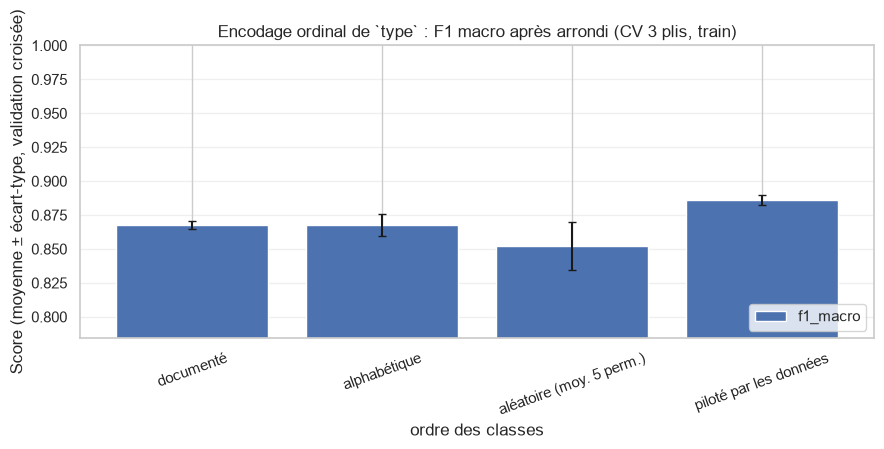

Gain F1 macro (piloté - documenté) = +0.0182 ; écart-type des permutations aléatoires = 0.0178
DÉCISION : ordre « piloté par les données (LDA, train) »  ->  ['normal', 'ransomware', 'scanning', 'backdoor', 'dos', 'mitm', 'xss', 'ddos', 'injection', 'password']
Ordre piloté par les données (information) : ['normal', 'ransomware', 'scanning', 'backdoor', 'dos', 'mitm', 'xss', 'ddos', 'injection', 'password']


In [19]:
fig, ax = plt.subplots(figsize=(9, 4.5))
U.plot_cv_comparison(summary, ["f1_macro"], ["f1_macro_std"], "Encodage ordinal de `type` : F1 macro après arrondi (CV 3 plis, train)", ax=ax)
ax.set_xlabel("ordre des classes"); plt.tight_layout(); U.savefig(fig, "01_encoding_study"); plt.show()

# ordre piloté par les données, ajusté sur TOUT le train (préprocessé)
pre_full = U.make_preprocessor(num_cols, cat_cols, scale=False)
dd_order = data_driven_order(dense(pre_full.fit_transform(X_train)), y_train["type"].to_numpy())
gain = summary.loc["piloté par les données", "f1_macro"] - summary.loc["documenté", "f1_macro"]
noise = summary.loc["aléatoire (moy. 5 perm.)", "f1_macro_std"]
use_dd = bool(gain > noise)
type_order = dd_order if use_dd else list(U.DOCUMENTED_TYPE_ORDER)
type_order_source = "piloté par les données (LDA, train)" if use_dd else "documenté"
print(f"Gain F1 macro (piloté - documenté) = {gain:+.4f} ; écart-type des permutations aléatoires = {noise:.4f}")
print(f"DÉCISION : ordre « {type_order_source} »  ->  {type_order}")
print("Ordre piloté par les données (information) :", dd_order)
report.update(encoding_study=summary.round(5).to_dict("index"), encoding_study_per_order=per.round(5).to_dict("index"),
              encoding_gain_vs_documented=float(gain), encoding_random_std=float(noise),
              type_order=type_order, type_order_source=type_order_source, type_order_data_driven=dd_order)

**Lecture.** La décision est mécanique (règle ci-dessus). Quel que soit l'ordre retenu, il n'est qu'une **commodité de codage** : les notebooks 04 et 05
le lisent dans `config.json`, comparent l'arrondi à des seuils optimisés sur la validation, et ajoutent un **classifieur de référence** (non demandé) qui n'a
pas besoin d'ordre. Les métriques « à ±1 classe » n'ont de sens que si l'ordre est réellement ordinal : à lire avec cette réserve.

## 10. Sauvegarde des artefacts

`type_code` est calculé **avec l'ordre retenu** au §9 ; l'ordre, sa provenance et l'étude sont écrits dans `config.json`.

In [20]:
to_code, _ = U.type_maps(type_order)
for y in (y_train, y_valid, y_test):
    y["type_code"] = y["type"].map(to_code).astype("int8")
for n, X, y in [("train", X_train, y_train), ("valid", X_valid, y_valid), ("test", X_test, y_test)]:
    X[keep].to_parquet(U.PROC_DIR / f"X_{n}.parquet"); y[["label", "type", "type_code"]].to_parquet(U.PROC_DIR / f"y_{n}.parquet")
config = {"numeric_cols": num_cols, "categorical_cols": cat_cols, "type_order": type_order, "type_order_source": type_order_source,
          "encoding_study": summary.round(5).to_dict("index"), "random_state": U.RANDOM_STATE,
          "split_sizes": {"train": len(X_train), "valid": len(X_valid), "test": len(X_test)},
          "removed_columns": {**drop_reason, **removed}}
(U.PROC_DIR / "config.json").write_text(json.dumps(config, indent=2, ensure_ascii=False), encoding="utf-8")
report.update(n_features=len(keep), numeric_cols=num_cols, categorical_cols=cat_cols, removed_columns=config["removed_columns"])
U.save_result("prep", report)
print(f"{len(keep)} variables finales ({len(num_cols)} numériques, {len(cat_cols)} catégorielles)")
print("Numériques :", num_cols); print("Catégorielles :", cat_cols)
print("Fichiers :", sorted(p.name for p in U.PROC_DIR.iterdir()))

35 variables finales (26 numériques, 9 catégorielles)
Numériques : ['dst_port', 'duration', 'src_bytes', 'dst_bytes', 'missed_bytes', 'src_pkts', 'src_ip_bytes', 'dst_pkts', 'dst_ip_bytes', 'dns_qclass', 'dns_rcode', 'http_request_body_len', 'http_response_body_len', 'http_status_code', 'has_http', 'has_ssl', 'has_weird', 'total_bytes', 'total_pkts', 'bytes_ratio', 'pkts_ratio', 'bytes_per_sec', 'pkts_per_sec', 'ip_overhead_src', 'ip_overhead_dst', 'same_ports']
Catégorielles : ['proto', 'service', 'conn_state', 'dns_AA', 'dns_RD', 'dns_RA', 'dns_rejected', 'src_port_bucket', 'dst_port_bucket']
Fichiers : ['X_test.parquet', 'X_train.parquet', 'X_valid.parquet', 'config.json', 'y_test.parquet', 'y_train.parquet', 'y_valid.parquet']


### Contrôles d'intégrité sur les fichiers écrits
Relecture des parquet : cohérence `label` / `type` / `type_code`, absence de colonnes interdites, recouvrement nul entre splits.

In [21]:
cfg = U.load_config(); order = U.get_type_order(cfg); t2c, _ = U.type_maps(order)
S = {n: U.load_split(n) for n in ("train", "valid", "test")}
for n, (X, y) in S.items():
    assert len(X) == len(y) and (y["label"].to_numpy() == (y["type"] != "normal").to_numpy()).all()
    assert (y["type"].map(t2c).to_numpy() == y["type_code"].to_numpy()).all()
    assert not {"src_port", "src_internal", "dst_internal", "src_ip", "dst_ip", "label", "type"} & set(X.columns)
assert U.cross_split_overlap(S["train"][0], S["valid"][0]) == 0 and U.cross_split_overlap(S["train"][0], S["test"][0]) == 0
assert U.cross_split_overlap(S["valid"][0], S["test"][0]) == 0
print("Tous les contrôles passent. Ordre :", order)

Tous les contrôles passent. Ordre : ['normal', 'ransomware', 'scanning', 'backdoor', 'dos', 'mitm', 'xss', 'ddos', 'injection', 'password']


## Résumé de la préparation

- Valeurs `-` converties en `NaN` ; valeurs invalides contrôlées ; `label == (type != 'normal')` vérifié.
- **`src_port` et les indicateurs dérivés des IP écartés** ; colonnes quasi vides remplacées par `has_*`.
- Déduplication + conflits **avant** le split, puis **déduplication inter-splits dans l'espace final** (recouvrement = 0, vérifié).
- Sélection de variables sur le train seul ; `log1p` sur les queues lourdes (aucune ligne supprimée) ; standardisation seulement pour le SVM.
- Équilibrage : au train uniquement (aperçu ici ; comparaison par validation croisée dans 02-05).
- **Ordre ordinal de `type` choisi par une étude** (documenté vs alphabétique vs aléatoire vs piloté par les données) et enregistré dans `config.json`.